# Twelfth Night: How Does Viola's Disguise Connect the Two Households?
CTS 2000 Group 6 · Abbey Altieri, Mason Helman, Soumya Patel, Krish Shah, Myra Thomas

## 1. Introduction

### The play
Twelfth Night is a Shakespeare comedy in 5 acts. Viola is shipwrecked and dresses up as a young man called Cesario so she can work for Duke Orsino. Orsino sends Cesario to win over Countess Olivia for him, but Olivia falls for Cesario instead. So the play has two separate worlds: Orsino's court and Olivia's household. Viola, as Cesario, is the one who keeps going between them. Everything gets sorted out in Act 5 when her twin brother Sebastian shows up and she reveals who she is.

### Our question
**How does Viola's disguise connect the divided households of Twelfth Night, and which computational methods capture it most accurately?**

### Our data
We use the Folger Shakespeare edition of the play. In data_cleaning.ipynb we turned it into a table with one row per speech.

In [4]:
import pandas as pd

play = pd.read_csv('data/twelfth_night_speeches.csv')

print(len(play), 'speeches and', play['lines'].sum(), 'lines')
play.head()

926 speeches and 2634 lines


,act,scene,speaker,lines,text,persona,clean_text
0,1,1,ORSINO,15,"If music be the food of love, play on.\nGive m...",ORSINO,music food love play give excess surfeit appet...
1,1,1,CURIO,1,"Will you go hunt, my lord?",CURIO,go hunt lord
2,1,1,ORSINO,1,"What, Curio?",ORSINO,curio
3,1,1,CURIO,1,The hart.,CURIO,hart
4,1,1,ORSINO,7,"Why, so I do, the noblest that I have.\nO, whe...",ORSINO,noble mine eye see olivia first methought purg...


What each column means:
- act and scene: where the speech happens
- speaker: who is talking (Feste is FOOL, Sir Toby is TOBY)
- lines: how many lines of the play the speech takes up
- text: the speech itself
- persona: same as speaker, except Viola's speeches say CESARIO when she is in disguise
- clean_text: the speech after cleaning (stopwords removed and words lemmatized, from week 6)

Here is the first speech of the play:

In [ ]:
first = play.loc[0]
print(first['speaker'], '- Act', first['act'], 'Scene', first['scene'])
print(first['text'])
print()
print('After cleaning:', first['clean_text'])

ORSINO - Act 1 Scene 1
If music be the food of love, play on.
Give me excess of it, that, surfeiting,
The appetite may sicken and so die.
That strain again! It had a dying fall.
O, it came o'er my ear like the sweet sound
That breathes upon a bank of violets,
Stealing and giving odor. Enough; no more.
'Tis not so sweet now as it was before.
O spirit of love, how quick and fresh art thou,
That, notwithstanding thy capacity
Receiveth as the sea, naught enters there,
Of what validity and pitch soe'er,
But falls into abatement and low price
Even in a minute. So full of shapes is fancy
That it alone is high fantastical.

After cleaning: music food love play give excess surfeit appetite may sicken die strain die fall come ear like sweet sound breathe bank violet steal give odor enough sweet spirit love quick fresh notwithstanding capacity receiveth sea naught enters validity pitch fall abatement low price even minute full shape fancy alone high fantastical


### Two versions of the data
Viola is one person, but the other characters think Cesario is someone else. So we made two versions of the data:
1. **Combined:** Viola and Cesario count as one person (the speaker column)
2. **Separate:** Viola and Cesario count as two people (the persona column)

Here is how many lines each character has in both versions:

In [ ]:
combined = play.groupby('speaker')['lines'].sum().sort_values(ascending=False)
separate = play.groupby('persona')['lines'].sum().sort_values(ascending=False)

print('Combined (Viola = Cesario):')
print(combined.head(6))
print()
print('Separate (Viola and Cesario apart):')
print(separate.head(6))

Combined (Viola = Cesario):
speaker
TOBY        357
VIOLA       344
OLIVIA      328
FOOL        318
MALVOLIO    297
ORSINO      226
Name: lines, dtype: int64

Separate (Viola and Cesario apart):
persona
TOBY        357
OLIVIA      328
FOOL        318
MALVOLIO    297
CESARIO     257
ORSINO      226
Name: lines, dtype: int64


In [ ]:
# Viola's speeches split by who she is at that moment
play[play['speaker'] == 'VIOLA'].groupby('persona')['lines'].agg(['count', 'sum'])

,count,sum
persona,,
CESARIO,106,257
VIOLA,16,87


In the combined version Viola has the 2nd most lines in the play (344). When we split her, Cesario has 257 of those lines and drops to 5th place, and Viola as herself only has 87. So most of what she says in the play, she says in disguise. This is why we compare both versions in the rest of the notebook, since the answer can change depending on which one we use.

## Why the Other Visualizations Were Less Effective
We decided to explore several visualization methods before choosing the approach that best answered our research questions. Although Abbey’s and Soumya’s visualizations provided useful insights into the characters and their dialogue, they were less effective at showing how relationships and interactions develop throughout the play. However, each method still contributed valuable information to our overall analysis.
### Visualization 1: Character Lines Spoken (Abbey)
Abbey’s visualization compares the total number of lines spoken by each character throughout the play. This is useful for identifying which characters are the most prominent in terms of dialogue and establishing who contributes the most to the overall conversation.
However, the visualization does not show who characters are speaking to or how their interactions change between acts. For example, a character having a high number of spoken lines does not necessarily mean they have the most connections or influence over the relationships in the play. It also cannot clearly demonstrate how characters connect Orsino’s court with Olivia’s household.
Therefore, while this visualization provides useful context about the distribution of dialogue, it does not fully address our research questions about character relationships and interactions.


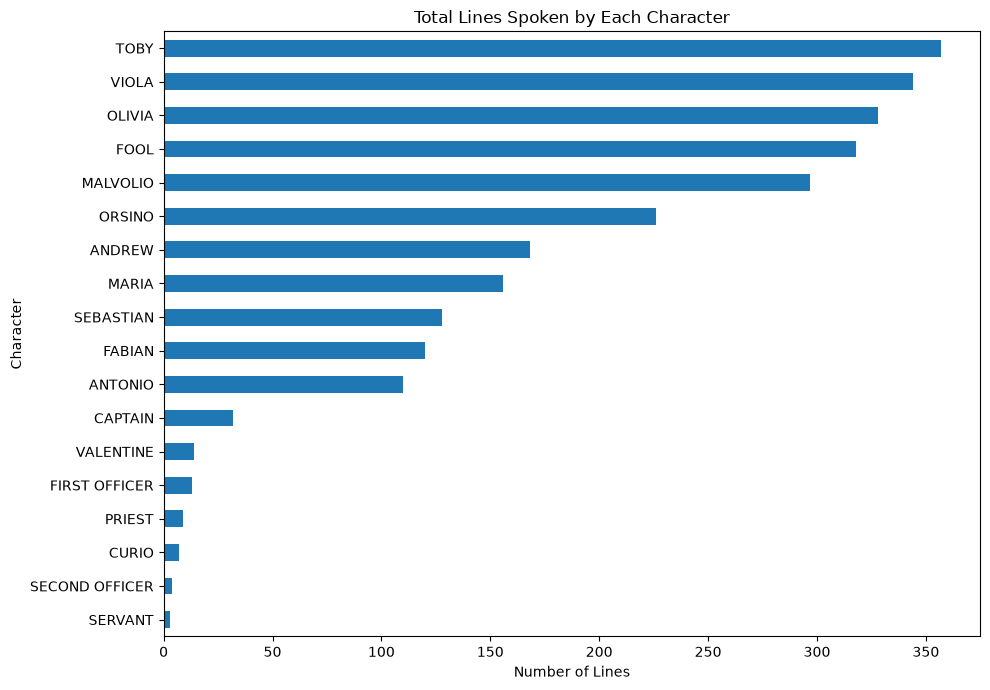

In [5]:
import matplotlib.pyplot as plt

character_line_count = play.groupby("speaker")["lines"].sum().sort_values()

plt.figure(figsize=(10, 7))
character_line_count.plot(kind="barh")

plt.title("Total Lines Spoken by Each Character")
plt.xlabel("Number of Lines")
plt.ylabel("Character")
plt.tight_layout()
plt.show()

### Visualization 2: Word Frequency and Vocabulary Comparisons (Soumya)
Soumya’s visualizations explore differences in the vocabulary used by characters and groups throughout the play. These figures provide a different perspective by focusing on the language itself rather than simply counting lines or mapping interactions.

Soumya’s first visualization compares the distinctive vocabulary used by Orsino’s court and Olivia’s household. This helps illustrate how the two social groups develop different linguistic identities. However, differences in word frequency do not necessarily reveal how characters interact or how relationships connect the two households.

![Court vs. Household Words](figures/court_vs_household_words.png)

The second visualization compares Viola’s vocabulary when speaking with Orsino and Olivia. This is particularly useful for exploring how Viola adapts her language depending on the person she is interacting with. It provides insight into her disguise and how she navigates the two households. However, it focuses on vocabulary rather than the development of relationships across the entire play.

![Viola's Vocabulary with Orsino and Olivia](figures/viola_orsino_vs_olivia.png)

The final visualization explores which characters use vocabulary similar to both Orsino and Olivia. This can help identify shared linguistic patterns between the two households. However, characters using similar words does not necessarily mean they interact directly or have meaningful relationships with one another.

![Who Talks Like Both?](figures/who_talks_like_both.png)

Overall, Soumya’s visualizations provide valuable insight into language, characterization, and the differences between the two households. They are especially useful for understanding how Viola's language changes depending on her social context. However, they do not directly map character interactions or show how relationships evolve throughout the five acts. This is why they were less effective as the primary method for answering our research questions.

## Why Visualization 2?


When we compared all of our visualisations and what information they could provide in terms of answering our research questions, Krish’s method of mapping using co-presence networks emerged as the clear frontrunner in terms of provided information. Co-presence networks involve the process of analyzing character’s interactions with each other over a designated space in time(in our case, mapping the changes between character interactions across the play’s 5 acts) and comparing their relationships through frequency of interaction. We decided that this was the most effective method in our process when we decided on using 2 datasets; whereas the other visualizations created very similar representations of data when separating viola/cesario and not, the co-presence networks massively warp depending on if they are being counted as one character or two, giving us a more easy to interpret visual representation of exactly how the lies and unknowns in the play affect the perceived relationships of the characters. Below is an example of how these networks evolve over time, displaying the introduction of new characters into the narrative across the play’s acts, and how networks form and connect throughout the plot. They start simplistic and rapidly increase complexity as more characters enter our space of analysis.


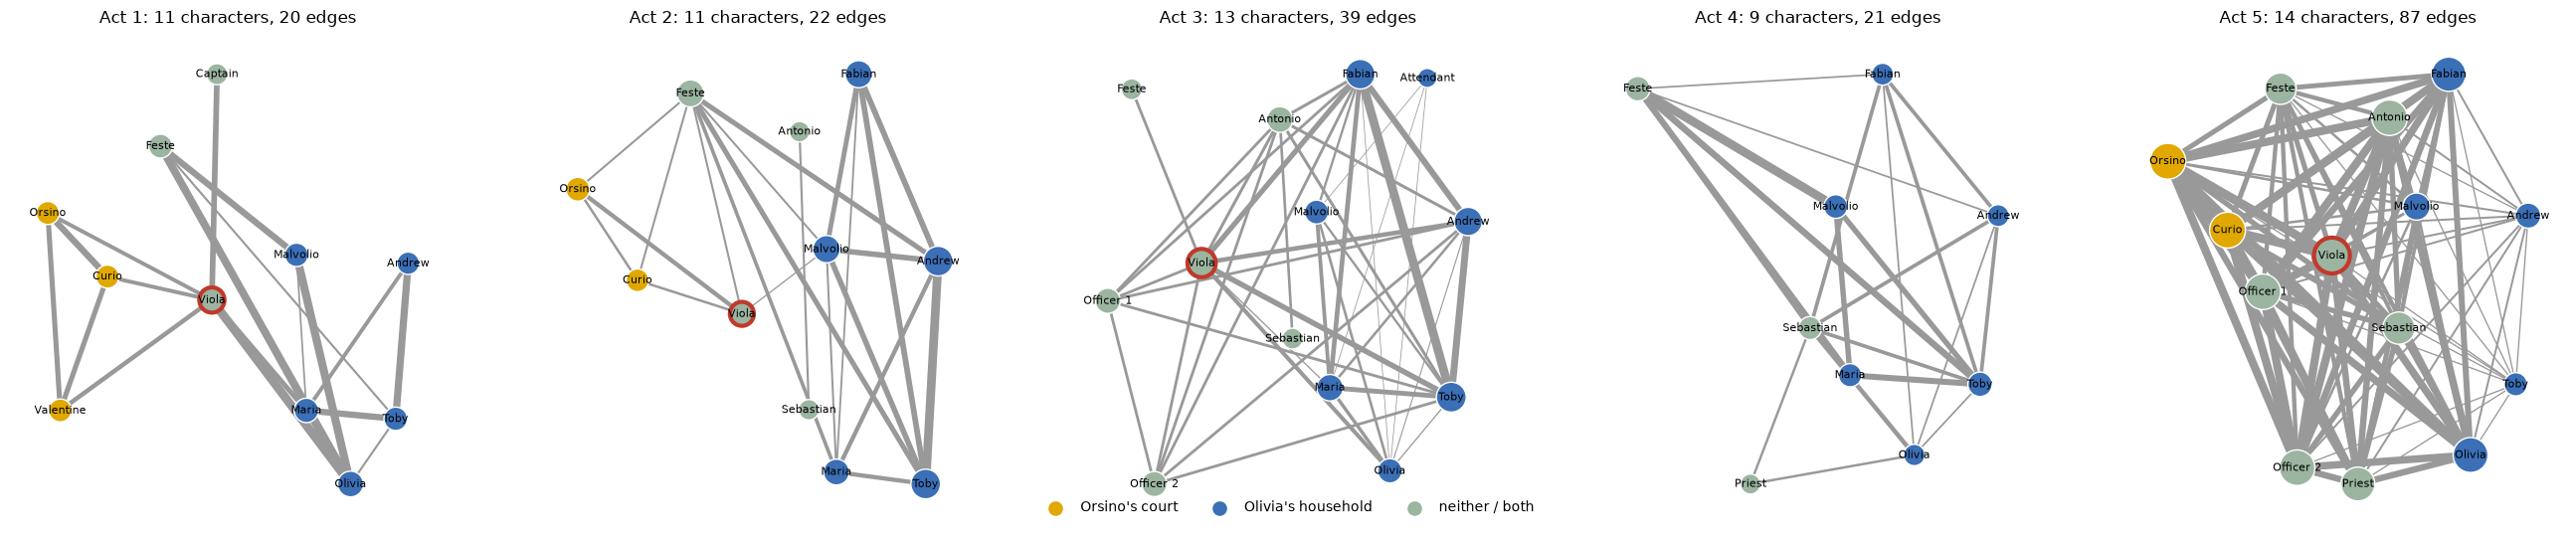

As is visible, the co-presence networks allow a level of elevated complexity and understanding when analyzing character relationships specifically, allowing us to break out of the purely statistical analysis of the alternate visualizations and focus more on relationship webs. This was only heightened when we applied the method to both datasets, as seen in the following section.

In short, our group believes that for a relationship chart as complex and intentionally misleading as Twelfth Night’s can be, the co-presence networks provide an extremely effective method of analysis that retains detail while broadly expanding on the differences in perceived relationships between the characters, due to the two-faced nature of Viola/Cesario.


---
## 2. Visualization 2: Who Shares the Stage? (Krish)

**How this part answers it.** We build two networks from the play's XML: **A. Co-presence** (who is on stage together) and **K. Kim's exchange** (Kim's 2024 rule that *everyone on stage hears the speaker*).
- **How the disguise connects the households:** we measure who bridges Orsino's court and Olivia's household (2.6), then split Viola into Viola and Cesario to see which persona does the connecting (2.7).
- **Which methods capture it most accurately:** we check our rebuild against Kim's published files (2.3), compare A and K side by side (2.5), and show the scene where both methods fail (2.8).

#### How this builds on earlier work
- **Short paper.** It argues that Kim's rule misreads hiding, eavesdropping and asides, and that merging Viola and Cesario hides the disguise. This notebook tests both points.
- **Code reproduction (Kim 2024).** Krish rebuilt Kim's onstage and exchange matrices; here we check them against the files Kim published (Section 2.3), plus the centralization numbers from the reproduction video.


#### Presenting
In one sentence per section: (2.1) we load the play; (2.2–2.3) we turn it into tables of who is on stage and check them against Kim; (2.5) we draw two ways of connecting characters; (2.6) we find who connects the two households; (2.7) we split Viola and Cesario; (2.8) we show the letter scene where both methods go wrong.

### 2.1 Dataset

We use the Folger edition of *Twelfth Night* in TEI XML. The course points to the Folger Digital Texts site for this kind of file; we take the copy that Kim (2024) published in his repository.

*Sections 2.1 to 2.3 load the play and build the two networks this part needs (A and K).*

In [ ]:
import os, re, requests
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from lxml import etree

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

XML_URL = ("https://raw.githubusercontent.com/hkim1596/shakespearean_character_network/"
           "main/data/Twelfth%20Night.xml")          # fix #1 from the reproduction: real file name
XML_PATH = "data/Twelfth Night.xml"
os.makedirs("data", exist_ok=True)
# only download the play if we don't already have it
if not os.path.exists(XML_PATH):
    response = requests.get(XML_URL)
    response.raise_for_status()                     # a failed download now stops right here
    with open(XML_PATH, "wb") as f:
        f.write(response.content)
print("XML file:", XML_PATH, "-", os.path.getsize(XML_PATH), "bytes")

XML file: data/Twelfth Night.xml - 2685594 bytes


#### What is in the data?
Three kinds of tags matter to us:
- `<sp who="#Orsino_TN">`: a **speech**, with its speaker
- `<stage type="entrance|exit|business|delivery">`: **stage directions**; `delivery` holds things like "aside" and "to Maria"
- `<milestone unit="ftln" ana="#verse">`: a **line marker**, tagged verse or prose

In [ ]:
TEI = "{http://www.tei-c.org/ns/1.0}"
XMLID = "{http://www.w3.org/XML/1998/namespace}id"
root = etree.parse(XML_PATH).getroot()

first_sp = root.find(f".//{TEI}sp")
print(etree.tostring(first_sp, pretty_print=True).decode()[:900])

print("Stage-direction types:", dict(Counter(s.get("type") for s in root.iter(TEI + "stage"))))

<sp xmlns="http://www.tei-c.org/ns/1.0" xml:id="sp-0001" who="#Orsino_TN">
<speaker xml:id="spk-0001">
<w xml:id="w0000340">ORSINO</w>
</speaker>
<ab xml:id="ab-0001">
<lb xml:id="lb-00006"/>
<milestone unit="ftln" xml:id="ftln-0001" n="1.1.1" ana="#verse" corresp="#w0000350 #c0000360 #w0000370 #c0000380 #w0000390 #c0000400 #w0000410 #c0000420 #w0000430 #c0000440 #w0000450 #c0000460 #w0000470 #p0000480 #c0000490 #w0000500 #c0000510 #w0000520 #p0000530"/>
<w xml:id="w0000350" n="1.1.1">If</w>
<c xml:id="c0000360" n="1.1.1"> </c>
<w xml:id="w0000370" n="1.1.1">music</w>
<c xml:id="c0000380" n="1.1.1"> </c>
<w xml:id="w0000390" n="1.1.1">be</w>
<c xml:id="c0000400" n="1.1.1"> </c>
<w xml:id="w0000410" n="1.1.1">the</w>
<c xml:id="c0000420" n="1.1.1"> </c>
<w xml:id="w0000430" n="1.1.1">food</w>
<c xml:id="c0000440" n="1.1.1"> </c>
<w xml:id="w0000450" n="1.1.1">of</w>
<c xml:id="c0000460" n
Stage-direction types: {'entrance': 62, 'exit': 62, 'business': 49, 'delivery': 120, 'mixed': 1}


### 2.2 Parsing the play into a *speech table*

One pass through the XML, in document order, does three jobs:
1. **Kim's logic.** Keep a list of who is on stage: entrances add names, exits remove them. Save a snapshot at every line marker.
2. **Our additions.** For each speech, record act, scene, words, verse/prose, and whether Viola is speaking as **Viola or Cesario**.

In [ ]:
def clean_id(raw):
    """'#Orsino_TN' -> 'Orsino' (same cleaning as Kim's code)."""
    return re.sub(r"_[^\s,]*", "", raw.replace("#", ""))

def who_list(el):
    return [clean_id(w) for w in el.get("who", "").split()]

def speech_text(sp):
    """Words and punctuation of a speech, leaving out stage directions and the speaker label."""
    out = ""
    for node in sp.iter(TEI + "w", TEI + "pc"):
        if any(a.tag in (TEI + "stage", TEI + "speaker") for a in node.iterancestors()):
            continue
        out += (node.text or "") if node.tag == TEI + "pc" else " " + (node.text or "")
    return out.strip()

def persona_at(on_stage, act, scene, revealed):
    """Is Viola 'Viola' or 'Cesario' at this moment?
    Viola when she speaks as herself (scene 1.2, after her reveal in 5.1, or when only the
    Captain / nobody else is on stage). Cesario whenever anyone else is watching."""
    if (act, scene) == (1, 2) or revealed:
        return "Viola"
    # basically: if anyone besides the Captain is around, she is acting as Cesario
    return "Viola" if not (set(on_stage) - {"Viola", "Captain"}) else "Cesario"

In [ ]:
def parse_play(root):
    # running list of who is on stage right now (same idea as Kim's code)
    on_stage = []
    timeline, ftln_meta, stage_events, speeches = {}, {}, [], []
    act = scene = None
    revealed, last_ftln = False, None

    for el in root.iter(TEI + "div1", TEI + "div2", TEI + "sp", TEI + "stage", TEI + "milestone"):
        if el.tag == TEI + "div1":
            act = int(el.get("n"))
        elif el.tag == TEI + "div2":
            scene = int(el.get("n"))

        elif el.tag == TEI + "milestone" and el.get("unit") == "ftln":
            fid = el.get(XMLID); last_ftln = fid
            timeline[fid] = list(on_stage)                      # Kim: snapshot of who is on stage
            ftln_meta[fid] = dict(act=act, scene=scene, n=el.get("n"), ana=el.get("ana"),
                                  persona=persona_at(on_stage, act, scene, revealed))

        elif el.tag == TEI + "stage":
            typ, who = el.get("type"), who_list(el)
            text = " ".join("".join(el.itertext()).split())
            if typ == "entrance" and el.get("who") is not None:
                on_stage = list(set(on_stage + who))
            elif typ == "exit" and el.get("who") is not None:
                on_stage = [c for c in on_stage if c not in who]
            if typ in ("entrance", "exit") and who:
                stage_events.append(dict(act=act, scene=scene, type=typ, n_chars=len(who), who=who))

        elif el.tag == TEI + "sp":
            speakers = who_list(el)
            speaker = speakers[0]
            ab = el.find(".//" + TEI + "ab")
            n_words = len(re.findall(r"\S+", "".join(ab.itertext()))) // len(speakers) if ab is not None else 0
            text = speech_text(el)

            if speaker == "Viola" and act == 5 and scene == 1 and re.search(r"\bI am Viola\b", text):
                revealed = True
            ms = [m.get("ana") for m in el.iter(TEI + "milestone") if m.get("unit") == "ftln"]
            persona = persona_at(on_stage, act, scene, revealed)

            # ---- Network K: Kim's rule, everyone else on stage hears (self if alone) ----
            aud_kim = [c for c in on_stage if c != speaker] or [speaker]

            speeches.append(dict(sp_id=el.get(XMLID), act=act, scene=scene, speaker=speaker, n_words=n_words,
                                 verse_lines=ms.count("#verse"), prose_lines=ms.count("#prose"),
                                 n_lines=len(ms), first_ftln=last_ftln, persona=persona,
                                 on_stage=list(on_stage), aud_kim=aud_kim, text=text))
    sp_df = pd.DataFrame(speeches)
    return sp_df, timeline, pd.DataFrame(ftln_meta).T, pd.DataFrame(stage_events)

speeches, timeline, ftln_meta, stage_events = parse_play(root)
print(f"{len(speeches)} speeches, {len(timeline)} line markers, {len(stage_events)} entrance/exit directions")
speeches[["act", "scene", "speaker", "n_words", "persona", "aud_kim", "text"]].head(8)

926 speeches, 2634 line markers, 124 entrance/exit directions


,act,scene,speaker,n_words,persona,aud_kim,text
0,1,1,Orsino,136,Cesario,"[MUSICIANS, ATTENDANTS.ORSINO.Curio, ATTENDANT...","If music be the food of love, play on. Give me..."
1,1,1,ATTENDANTS.ORSINO.Curio,8,Cesario,"[MUSICIANS, Orsino, ATTENDANTS.ORSINO]","Will you go hunt, my lord?"
2,1,1,Orsino,4,Cesario,"[MUSICIANS, ATTENDANTS.ORSINO.Curio, ATTENDANT...","What, Curio?"
3,1,1,ATTENDANTS.ORSINO.Curio,3,Cesario,"[MUSICIANS, Orsino, ATTENDANTS.ORSINO]",The hart.
4,1,1,Orsino,69,Cesario,"[MUSICIANS, ATTENDANTS.ORSINO.Curio, ATTENDANT...","Why, so I do, the noblest that I have. O, when..."
5,1,1,ATTENDANTS.ORSINO.Valentine,80,Cesario,"[ATTENDANTS.ORSINO, Orsino, MUSICIANS, ATTENDA...","So please my lord, I might not be admitted, Bu..."
6,1,1,Orsino,88,Cesario,"[ATTENDANTS.ORSINO, ATTENDANTS.ORSINO.Valentin...","O, she that hath a heart of that fine frame To..."
7,1,2,Viola,8,Viola,"[Captain, SAILORS]","What country, friends, is this?"


**The columns:** `aud_kim` = who hears the speech if *everyone on stage* does (Kim's rule, **K**) · `persona` = Viola or Cesario at that moment · `on_stage` = everyone on stage when the speech starts.

### 2.3 Network tools
One small set of functions builds both networks from the speech table. Each network is a table of weights between pairs of characters:

| Network | Edge between two characters = |
|---|---|
| **A. Co-presence** | lines they share the stage (Kim's *onstage* matrix) |
| **K. Everyone hears** | words spoken, heard by *everyone* on stage (Kim's *exchange* matrix) |

In [ ]:
def relabel(name, persona, split):
    """With split=True, 'Viola' becomes 'Viola' or 'Cesario' depending on the moment."""
    return persona if (split and name == "Viola") else name

def presence_matrix(split=False, act=None, scene=None):
    """Lines x characters (1 = on stage). Kim's stage_timeline."""
    rows = {}
    for fid, chars in timeline.items():
        m = ftln_meta.loc[fid]
        if (act and m["act"] != act) or (scene and m["scene"] != scene):
            continue
        rows[fid] = {relabel(c, m["persona"], split): 1 for c in chars}
    return pd.DataFrame(rows).T.fillna(0).astype(int).sort_index(axis=1)   # sorted = repeatable

def copresence(split=False, act=None, scene=None):
    """Kim's onstage matrix: lines x characters, multiplied by itself = lines each pair shares the stage."""
    X = presence_matrix(split, act, scene)
    M = X.to_numpy(copy=True).T @ X.to_numpy(copy=True)          # fix #2 from the reproduction: work on a copy
    np.fill_diagonal(M, 0)
    return pd.DataFrame(M, index=X.columns, columns=X.columns)

def exchange(key, split=False, act=None, scene=None):
    """Directed word counts speaker -> listener (key = aud_kim, Kim's everyone-hears rule)."""
    ex = defaultdict(lambda: defaultdict(int))
    for r in speeches.itertuples():
        if (act and r.act != act) or (scene and r.scene != scene):
            continue
        s = relabel(r.speaker, r.persona, split)
        for l in getattr(r, key):
            ex[s][relabel(l, r.persona, split)] += r.n_words
    return pd.DataFrame(ex).T.fillna(0).sort_index().sort_index(axis=1)

def symmetric(ex):
    """Turn 'A spoke to B' counts into 'A and B talked' counts (both directions added together)."""
    both = defaultdict(lambda: defaultdict(int))
    for s in ex.index:
        for l in ex.columns:
            if s != l and ex.loc[s, l] > 0:
                both[s][l] += ex.loc[s, l]
                both[l][s] += ex.loc[s, l]
    nodes = sorted(set(ex.index) | set(ex.columns))
    return pd.DataFrame(both, index=nodes, columns=nodes).fillna(0).astype(int)

# one dictionary per network so we can put them side by side
def build_networks(split=False, act=None, scene=None):
    return {"A. Co-presence": copresence(split, act, scene),
            "K. Kim's exchange": symmetric(exchange("aud_kim", split, act, scene))}

# only people who actually talk (the musicians and sailors never do)
SPEAKING = set(speeches["speaker"])
SHORT = {"TobyBelch": "Toby", "AndrewAguecheek": "Andrew", "ATTENDANTS.ORSINO.Curio": "Curio",
         "ATTENDANTS.ORSINO.Valentine": "Valentine", "ATTENDANTS.OLIVIA.1": "Attendant",
         "OFFICERS.1": "Officer 1", "OFFICERS.2": "Officer 2"}
short = lambda n: SHORT.get(n, n)

def to_graph(M, keep=None):
    """Table of weights -> networkx graph, built edge by edge like the course notebook 5-5."""
    keep = keep or (SPEAKING | {"Cesario"})
    G = nx.Graph()
    for a in M.index:
        if a in keep:
            G.add_node(short(a))                          # keep characters even if they have no links
    for a in M.index:
        for b in M.columns:
            if a in keep and b in keep and a != b and M.loc[a, b] > 0:
                G.add_edge(short(a), short(b), weight=M.loc[a, b])
    return G

#### Check against Kim's published output (the reproduction)
If our rebuilt version of Kim's two networks is right, it should match the files in his repository exactly. This is the same check we did in the code reproduction.

In [ ]:
AUTHOR = "https://raw.githubusercontent.com/hkim1596/shakespearean_character_network/main/"
def author_csv(path):
    try:
        return pd.read_csv(AUTHOR + path.replace(" ", "%20"), index_col=0)
    except Exception as e:
        print("  (could not download", path, "-", type(e).__name__, ")")
        return None

# optional sanity check: these should match Kim's own files from our reproduction
onstage_author = author_csv("output_onstage/Twelfth Night_onstage.csv")
exchange_author = author_csv("output_exchange/Twelfth Night_exchange.csv")

if onstage_author is not None:
    mine = presence_matrix().T.reindex(index=onstage_author.index, columns=onstage_author.columns, fill_value=0)
    print("On-stage presence (characters x lines) identical to the author's:",
          bool((mine.to_numpy() == onstage_author.astype(int).to_numpy()).all()))
if exchange_author is not None:
    mine = exchange("aud_kim").reindex(index=exchange_author.index, columns=exchange_author.columns, fill_value=0)
    print("Exchange matrix (words) identical to the author's:",
          bool(np.allclose(mine.to_numpy(), exchange_author.to_numpy())))

On-stage presence (characters x lines) identical to the author's: True
Exchange matrix (words) identical to the author's: True


And the whole-play centralization numbers from the reproduction video (degree 0.3619, betweenness 0.0210), computed on Kim's matrix with every node (musicians and sailors included):

In [ ]:
def degree_centralization(G):                     # Kim's function
    degrees = nx.degree(G)
    max_degree = max(dict(degrees).values())
    total = sum(max_degree - d for _, d in degrees)
    n = len(G.nodes)
    return total / ((n - 1) * (n - 2)) if n > 2 else 0

def betweenness_centralization(G):                # Kim's function
    b = nx.betweenness_centrality(G)
    mx = max(b.values())
    total = sum(mx - v for v in b.values())
    n = len(G.nodes)
    return total / ((n - 1) * (n - 2) / 2) if n > 2 else 0

A_all = copresence()
G_kim = to_graph(A_all, keep=set(A_all.index))       # every node, like Kim
print(f"Degree centralization:      {degree_centralization(G_kim):.4f}   (code reproduction video: 0.3619)")
print(f"Betweenness centralization: {betweenness_centralization(G_kim):.4f}   (code reproduction video: 0.0210)")

Degree centralization:      0.3619   (code reproduction video: 0.3619)
Betweenness centralization: 0.0210   (code reproduction video: 0.0210)


### 2.4 Drawing the networks: one layout, one colour code
Every picture uses the **same node positions** (court on the left, Olivia's household on the right, characters who belong to neither in the middle), so when two networks look different it is because their *edges* differ, not because the layout moved. Node size = how much interaction a character has; edge width = how much interaction a pair has; Viola/Cesario is outlined in red.

In [ ]:
COURT = {"Orsino", "Curio", "Valentine"}
HOUSEHOLD = {"Olivia", "Maria", "Malvolio", "Toby", "Andrew", "Fabian", "Attendant"}
side = lambda n: "court" if n in COURT else "household" if n in HOUSEHOLD else "unaligned"
SIDE_COLOR = {"court": "#e0a800", "household": "#3b6fb6", "unaligned": "#9bb5a0"}

nets = build_networks()
# same networks again, but Viola and Cesario count as two different people
nets_split = build_networks(split=True)

# Fixed positions (x, y) for every character: court on the left, household on the right,
# Viola in the middle. Placed by hand so every figure uses the same picture.
POS = {
    "Orsino": (-3.16, 0.52), "Curio": (-2.01, 0.14), "Valentine": (-2.92, -0.66),                      # court
    "Viola": (0.0, 0.0), "Cesario": (0.35, -0.45), "Feste": (-0.99, 0.92), "Captain": (0.1, 1.35),     # neither / both
    "Antonio": (1.11, 0.76), "Sebastian": (1.29, -0.4), "Priest": (0.5, -1.26),
    "Officer 1": (-1.33, -0.2), "Officer 2": (-0.67, -1.17),
    "Olivia": (2.67, -1.1), "Maria": (1.82, -0.66), "Malvolio": (1.63, 0.27), "Fabian": (2.25, 1.0),   # household
    "Attendant": (3.2, 0.98), "Andrew": (3.78, 0.22), "Toby": (3.54, -0.71),
}

def draw_net(G, ax, title="", pos=POS, label_size=9, scale=1.0, max_w=None):
    """Draw a network on our fixed layout (same nx.draw_networkx call as the course notebook)."""
    weights = [d["weight"] for _, _, d in G.edges(data=True)]
    top = max_w or max(weights, default=1)
    strength = dict(G.degree(weight="weight"))                 # total interaction of each character
    nx.draw_networkx(G, pos, ax=ax, font_size=label_size, edge_color="#999999",
                     width=[0.3 + 6 * scale * (w / top) ** 0.7 for w in weights],      # thicker = more interaction
                     node_color=[SIDE_COLOR[side(n)] for n in G.nodes],
                     node_size=[160 + 9 * strength[n] ** 0.5 for n in G.nodes],        # bigger = more interaction
                     edgecolors=["#c0392b" if n in ("Viola", "Cesario") else "white" for n in G.nodes],
                     linewidths=[3 if n in ("Viola", "Cesario") else 1 for n in G.nodes])
    ax.set_title(title, fontsize=12); ax.axis("off")

def legend(ax):
    for s, c in SIDE_COLOR.items(): ax.scatter([], [], c=c, s=90, label={"court": "Orsino's court", "household": "Olivia's household", "unaligned": "neither / both"}[s])
    ax.legend(loc="lower center", ncol=3, frameon=False, fontsize=10)

### 2.5 The whole play: sharing a stage vs. being heard by everyone
- **A. Co-presence**: who shares the stage.
- **K. Everyone hears**: Kim's exchange rule, where a speech counts as spoken to *everyone* on stage.

*In one sentence:* both pictures are almost the same, because everyone who shares a stage also "hears" everyone who speaks.

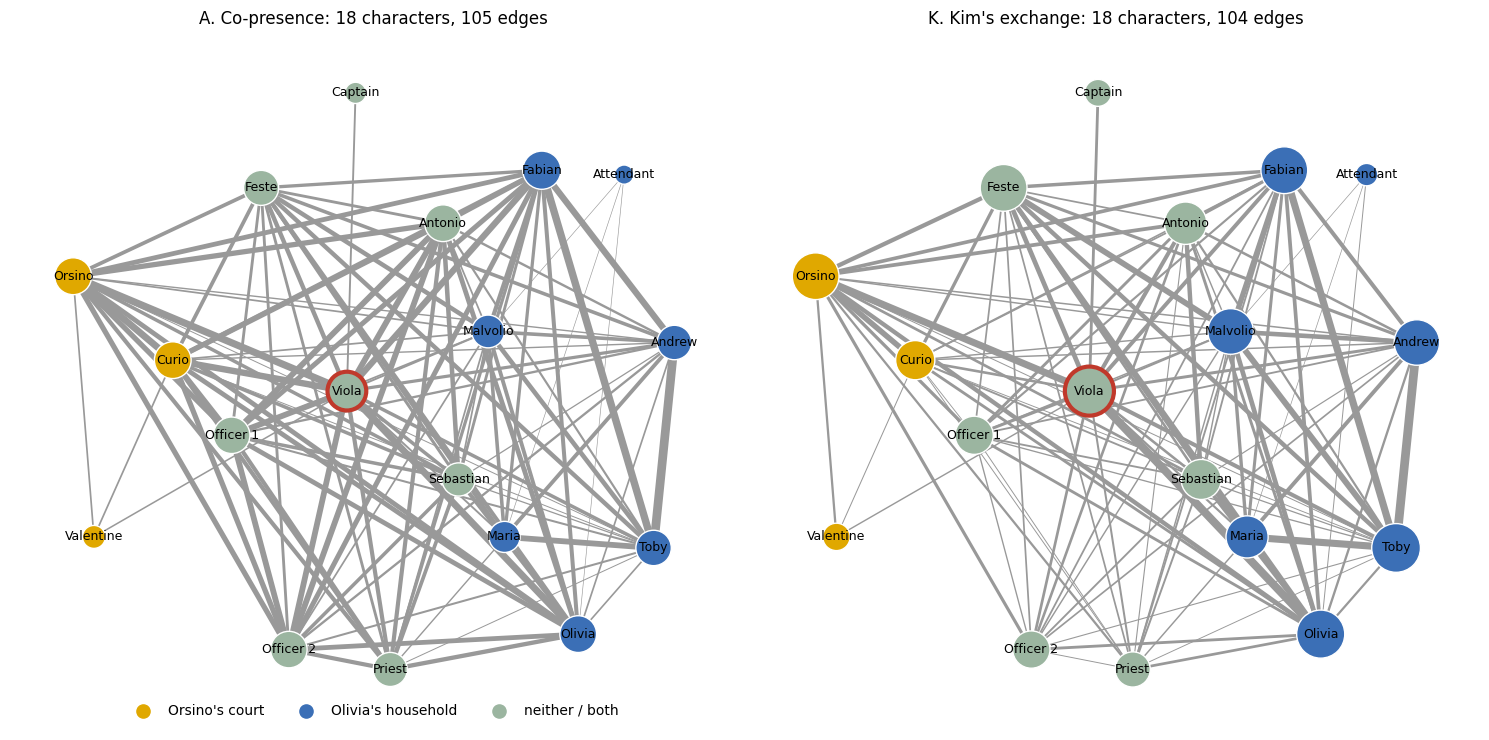

In [ ]:
# two ways of counting a connection, drawn on the same layout
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, name in zip(axes, ["A. Co-presence", "K. Kim's exchange"]):
    G = to_graph(nets[name])                     # turn the table of weights into a graph
    draw_net(G, ax, f"{name}: {G.number_of_nodes()} characters, {G.number_of_edges()} edges")
legend(axes[0]); plt.tight_layout(); plt.show()

### 2.6 How the disguise connects the households: who bridges Orsino's court and Olivia's household?
Households come from our character map (Feste, Viola/Cesario and the rest are "neither / both"). For every character we add up their weight to court members and to household members; the **bridge score** is high only if *both* are large.

*In one sentence:* Orsino and Olivia are never on stage together until the last scene, so someone else has to connect them.

In [ ]:
# list of every scene, used below to look at one scene at a time
scenes = speeches.groupby(["act", "scene"]).size().to_frame("speeches")

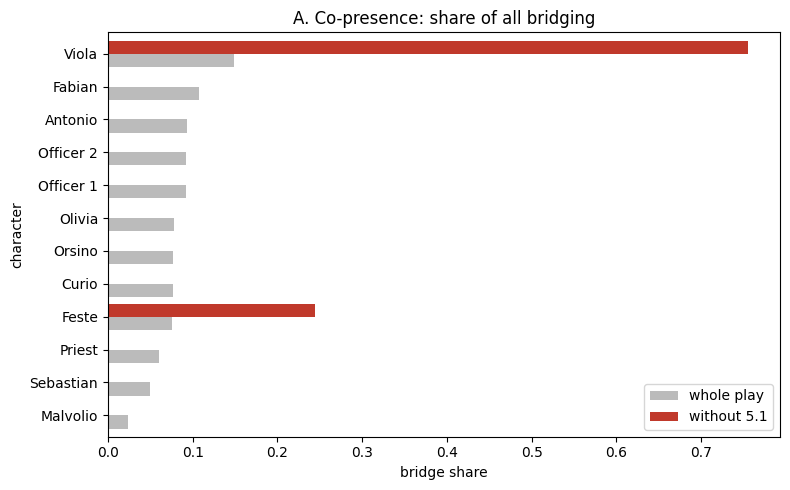

,whole play,without 5.1
character,,
Malvolio,0.02,0.00
Sebastian,0.05,0.00
Priest,0.06,0.00
Feste,0.08,0.24
Curio,0.08,0.00
Orsino,0.08,0.00
Olivia,0.08,0.00
Officer 1,0.09,0.00
Officer 2,0.09,0.00


In [ ]:
# rough idea: someone who talks to BOTH sides a lot is acting as a bridge
def bridge_table(M):
    G = to_graph(M); rows = []
    for n in G.nodes:
        wc = sum(G[n][m]["weight"] for m in G[n] if m in COURT and m != n)        # weight to Orsino's court
        wh = sum(G[n][m]["weight"] for m in G[n] if m in HOUSEHOLD and m != n)    # weight to Olivia's household
        rows.append(dict(character=n, side=side(n), to_court=wc, to_household=wh, bridge_score=2 * wc * wh / (wc + wh) if wc and wh else 0))
    t = pd.DataFrame(rows).set_index("character")
    t["bridge_share"] = t.bridge_score / t.bridge_score.sum()
    return t.sort_values("bridge_score", ascending=False)

def without_scene(act_scene, key):
    """The whole play minus one scene, by adding up every other scene's matrix."""
    parts = [build_networks(act=a, scene=s)[key] for a, s in scenes.index if (a, s) != act_scene]
    nodes = sorted(set().union(*[p.index for p in parts]))
    return sum(p.reindex(index=nodes, columns=nodes, fill_value=0) for p in parts)

A_whole = nets["A. Co-presence"]
A_no51 = without_scene((5, 1), "A. Co-presence")      # 5.1 puts almost everyone on stage, so we also look without it

d = pd.DataFrame({"whole play": bridge_table(A_whole).bridge_share, "without 5.1": bridge_table(A_no51).bridge_share}).fillna(0)
d = d[d.max(axis=1) > 0.02].sort_values("whole play")
d.plot.barh(color=["#bbbbbb", "#c0392b"], width=0.8, figsize=(8, 5))
plt.title("A. Co-presence: share of all bridging"); plt.xlabel("bridge share"); plt.tight_layout(); plt.show()
d.round(2)

**When are Orsino and Olivia on stage together?** Lines they share, scene by scene (scenes where they never meet are left out):

In [ ]:
# co-presence of just these two, for every scene
for a, s in scenes.index:
    w = copresence(act=a, scene=s)
    if "Orsino" in w.index and "Olivia" in w.columns and w.loc["Orsino", "Olivia"] > 0:
        print(f"Act {a} scene {s}: {w.loc['Orsino', 'Olivia']} lines together")

Act 5 scene 1: 316 lines together


In 5.1 almost everyone is on stage at once, so with that scene nearly everyone looks like a bridge. Without it the picture is sharper. Next, a direct test: **if we remove a character, how much further apart do the two households get?** (Distance between two characters = 1 / weight, averaged over all court-household pairs.)

In [ ]:
def cross_distance(G, remove=None):
    H = G.copy()
    if remove in H: H.remove_node(remove)
    for u, v, d in H.edges(data=True): d["dist"] = 1 / d["weight"]       # more interaction = shorter distance
    pairs = [(c, h) for c in COURT for h in HOUSEHOLD if c in H and h in H]
    ds = [nx.shortest_path_length(H, c, h, weight="dist") for c, h in pairs if nx.has_path(H, c, h)]
    return np.mean(ds) if ds else np.nan

rows = []
for label, M in {"whole play": A_whole, "without 5.1": A_no51}.items():
    G = to_graph(M); base = cross_distance(G)
    for cand in ["Viola", "Feste", "Sebastian", "Antonio"]:
        if cand in G:
            rows.append(dict(network=f"A. Co-presence, {label}", removed=cand, distance_increase_pct=round(100 * (cross_distance(G, cand) / base - 1), 1)))
pd.DataFrame(rows).pivot(index="removed", columns="network", values="distance_increase_pct")

network,"A. Co-presence, whole play","A. Co-presence, without 5.1"
removed,,
Antonio,0.0,0.0
Feste,0.0,0.0
Sebastian,0.0,0.0
Viola,0.0,32.4


### 2.7 Viola vs. Cesario: which persona does the connecting?
We split the node with a transparent rule (`persona_at`): **Viola** in scene 1.2, after her reveal in 5.1, or when nobody but the Captain is watching; **Cesario** whenever anyone else is on stage.

*In one sentence:* splitting her shows that Cesario is the one who meets everyone, while Viola mostly appears alone or with the Captain.

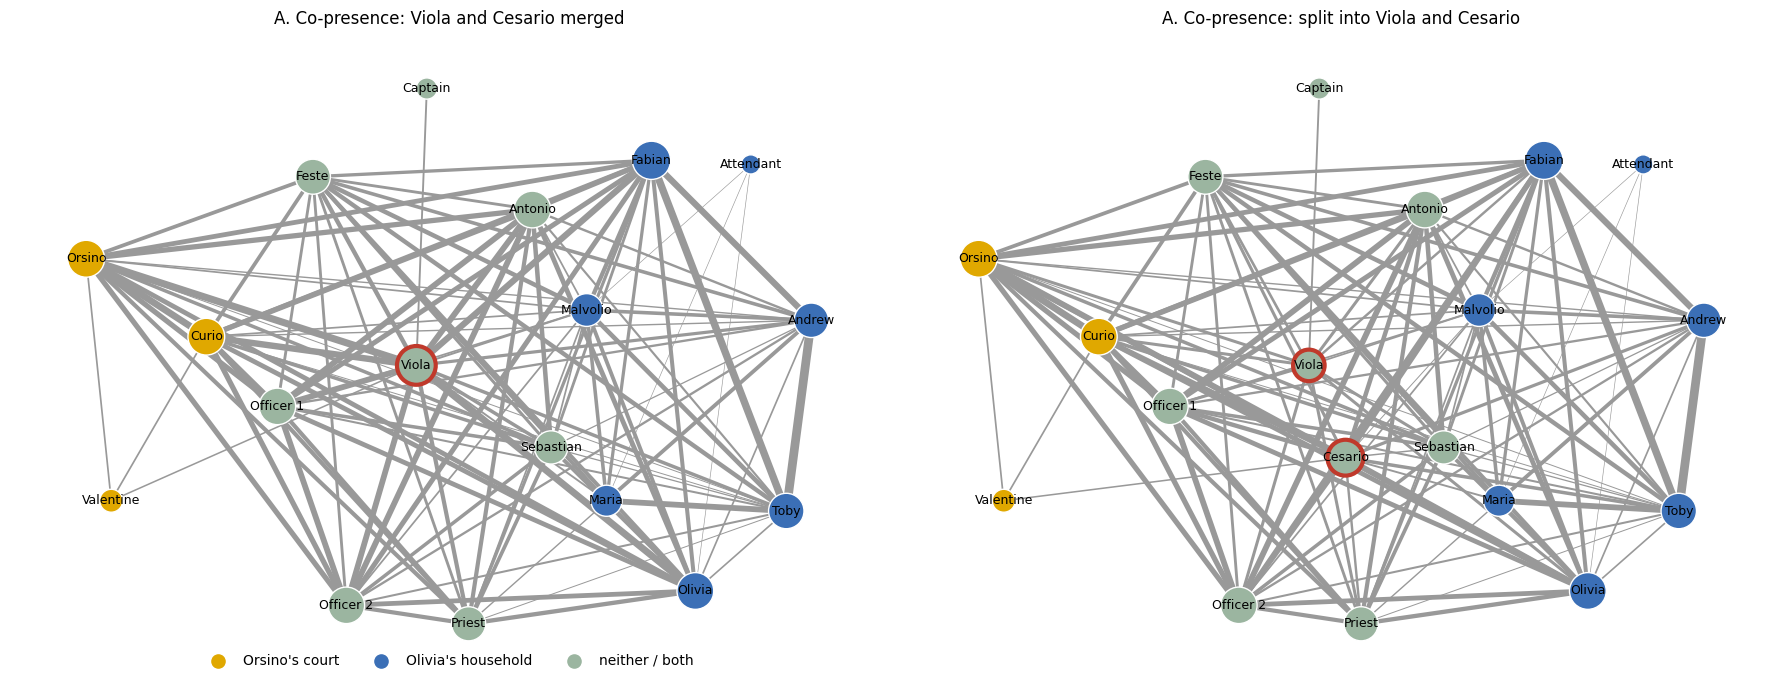

,node,strength,to_court,to_household,betweenness
0,Viola (merged),4726,1122,1530,0.162
1,Cesario,3169,820,1217,0.040
2,Viola (split),1557,302,313,0.111


In [ ]:
# same co-presence network, merged vs split
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
draw_net(to_graph(nets["A. Co-presence"]), axes[0], "A. Co-presence: Viola and Cesario merged")
draw_net(to_graph(nets_split["A. Co-presence"]), axes[1], "A. Co-presence: split into Viola and Cesario")
legend(axes[0]); plt.tight_layout(); plt.show()

rows = []
Gm, Gs = to_graph(nets["A. Co-presence"]), to_graph(nets_split["A. Co-presence"])
for label, G, node in [("Viola (merged)", Gm, "Viola"), ("Cesario", Gs, "Cesario"), ("Viola (split)", Gs, "Viola")]:
    if node in G:
        rows.append(dict(node=label, strength=round(G.degree(node, weight="weight")),
                         to_court=round(sum(G[node][m]["weight"] for m in G[node] if m in COURT)),
                         to_household=round(sum(G[node][m]["weight"] for m in G[node] if m in HOUSEHOLD)),
                         betweenness=round(nx.betweenness_centrality(G)[node], 3)))
pd.DataFrame(rows)

### 2.8 Where the methods fail: Act 2, Scene 5, the letter scene
Sir Toby, Sir Andrew and Fabian hide. Malvolio reads a forged letter and thinks he is alone. Here is the scene under the two *co-presence-style* rules. **Edge width is on one scale per panel.** Is Malvolio (centre, red) "connected" to the hiding men?

*In one sentence:* both of these rules say yes, even though Malvolio has no idea they are there.

This is the main problem Part 2 picks up: a network that only knows who is on stage cannot tell that the three men are hiding. Myra's speaking networks test whether counting actual conversation fixes it.

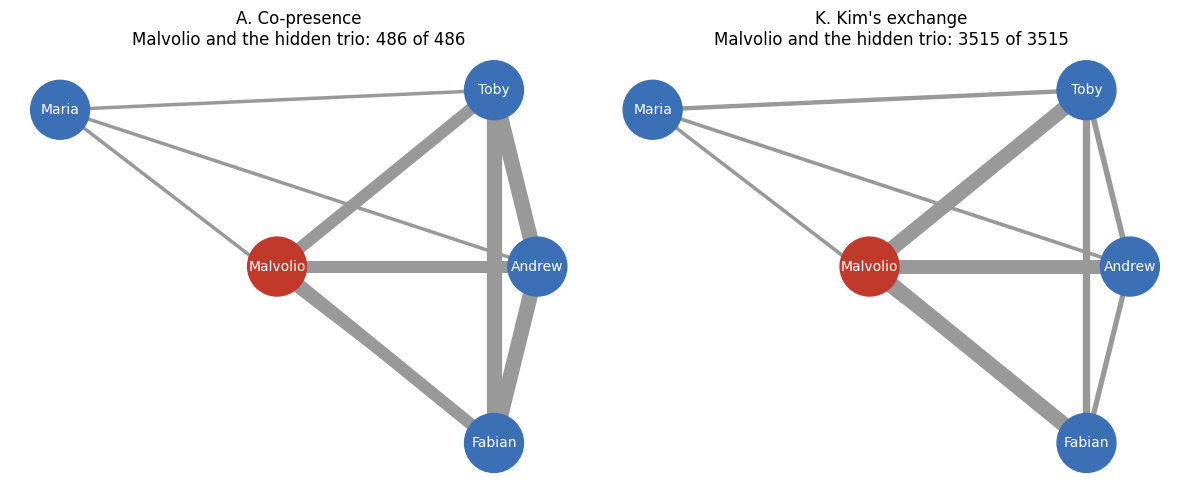

Malvolio speaks 1052 words in 2.5. Kim's rule counts all 1052 as spoken to each of the three hidden men.


,network,malvolio_total,with_the_hidden_trio,share
0,A. Co-presence,486,486,1.0
1,K. Kim's exchange,3515,3515,1.0


In [ ]:
# just the five people in the letter scene, easier to read than the whole cast
CASE = ["Malvolio", "TobyBelch", "AndrewAguecheek", "Fabian", "Maria"]
case_pos = {"Malvolio": (0, 0), "TobyBelch": (1.5, 0.9), "AndrewAguecheek": (1.8, 0), "Fabian": (1.5, -0.9), "Maria": (-1.5, 0.8)}
scene25 = build_networks(act=2, scene=5)
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["A. Co-presence", "K. Kim's exchange"]):
    M = scene25[name].reindex(index=CASE, columns=CASE, fill_value=0)
    G = to_graph(M, keep=set(CASE))
    pos = {short(k): v for k, v in case_pos.items()}
    weights = [d["weight"] for _, _, d in G.edges(data=True)]
    nx.draw_networkx(G, pos, ax=ax, node_size=1800, font_size=10, font_color="white", edge_color="#999999",
                     width=[1 + 10 * w / max(weights) for w in weights],
                     node_color=["#c0392b" if n == "Malvolio" else "#3b6fb6" for n in G.nodes])
    tot = M.loc["Malvolio"].sum(); trio = M.loc["Malvolio", CASE[1:4]].sum()
    ax.set_title(f"{name}\nMalvolio and the hidden trio: {trio:.0f} of {tot:.0f}"); ax.axis("off")
    rows.append(dict(network=name, malvolio_total=round(tot), with_the_hidden_trio=round(trio), share=round(trio / tot, 2)))
plt.tight_layout(); plt.show()

mal = speeches[(speeches.act == 2) & (speeches.scene == 5) & (speeches.speaker == "Malvolio")]
print(f"Malvolio speaks {mal.n_words.sum()} words in 2.5. Kim's rule counts all {mal.n_words.sum()} as spoken to each of the three hidden men.")
pd.DataFrame(rows)

### 2.9 What this part shows

**How does Viola's disguise connect the divided households?**
- **The households barely meet.** Orsino and Olivia share the stage only in the last scene, 5.1 (316 lines). For the rest of the play, someone else has to connect them.
- **Viola/Cesario is that connection.** Without 5.1, Viola/Cesario does 76% of all the bridging between court and household, and Feste does the rest. Removing Viola/Cesario pushes the two households about 32% further apart; removing Feste, Sebastian or Antonio changes nothing.
- **It is the disguise that does it.** Split into two people, Cesario has 106 speeches and links to both the court (820) and the household (1,217). Viola as herself has 16 speeches and far fewer links (302 and 313).

**Which methods capture it most accurately?**
- **Our rebuild of Kim's method is exact.** It matches his published onstage and exchange files, and the centralization numbers from the reproduction (0.3619 and 0.0210).
- **For the big picture, the two methods agree.** Kim's "everyone hears" network (K) matches co-presence (A) almost exactly (104 edges against 105 over the whole play, in 2.5), and both show Cesario as the bridge.
- **Both fail where the play is about hearing.** In the letter scene (2.5), both tie all of Malvolio's interaction to the three men hiding from him (all 1,052 of his words count as spoken to each of them), even though he thinks he is alone. A network that knows who is *addressed*, not just who is *present*, is needed for scenes built on hiding, eavesdropping and asides.

**Limitations.** Co-presence shows who is in the room, not who talks to whom. The Viola/Cesario split is a rule of thumb (`persona_at`). The households come from our character map. The distance test goes beyond the course.